In [1]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
df=pd.read_csv(r'E:\DataAnalytics\Cases\Wisconsin\BreastCancer.csv',index_col=0)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [3]:
X=df.drop('Class',axis=1)
y=df['Class']

In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26)

In [5]:
knn=KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Benign','Malignant']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [6]:
y_pred=knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.9476190476190476

In [7]:
Ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores=[]
for k in Ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['K','score'])
df_scores.sort_values('score',ascending=False).head()

,K,score
2,3,0.976190
4,5,0.971429
10,11,0.957143
12,13,0.957143
6,7,0.952381


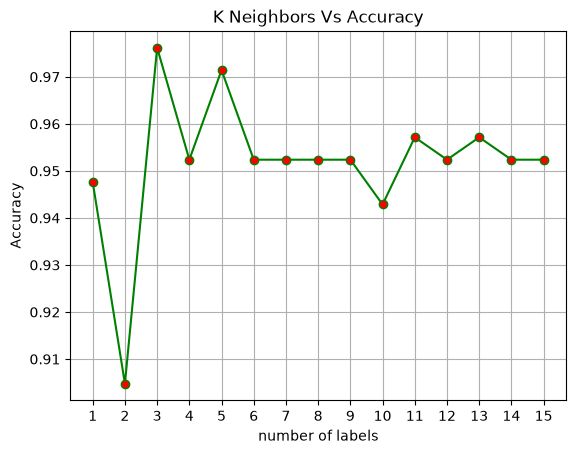

In [8]:
import matplotlib.pyplot as plt
plt.plot(df_scores.K,df_scores.score,marker='o',markerfacecolor='r',color='g')
plt.xticks(df_scores.K)
plt.title('K Neighbors Vs Accuracy')
plt.xlabel('number of labels')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show();


In [9]:
df=pd.read_csv(r'../../Cases/Vehicle Silhouettes/Vehicle.csv')
df.head()

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


In [10]:
X=df.drop('Class',axis=1)
y=df['Class']

In [11]:
df.isnull().sum().sum()

np.int64(0)

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26)

In [13]:
y.value_counts(normalize=True)*100,y_train.value_counts(normalize=True)*100

(Class
 bus     25.768322
 saab    25.650118
 opel    25.059102
 van     23.522459
 Name: proportion, dtype: float64,
 Class
 bus     26.351351
 saab    25.168919
 opel    24.831081
 van     23.648649
 Name: proportion, dtype: float64)

with Stratify

In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [15]:
y.value_counts(normalize=True)*100,y_train.value_counts(normalize=True)*100

(Class
 bus     25.768322
 saab    25.650118
 opel    25.059102
 van     23.522459
 Name: proportion, dtype: float64,
 Class
 bus     25.844595
 saab    25.675676
 opel    25.000000
 van     23.479730
 Name: proportion, dtype: float64)

### the stratify will maintain the proportion in the test set as same as the data set

In [16]:
Ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores=[]
for k in Ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['K','score'])
df_scores.sort_values('score',ascending=False)

,K,score
0,1,0.677165
1,2,0.673228
4,5,0.661417
6,7,0.661417
2,3,0.657480
10,11,0.657480
7,8,0.657480
8,9,0.653543
5,6,0.653543
3,4,0.649606


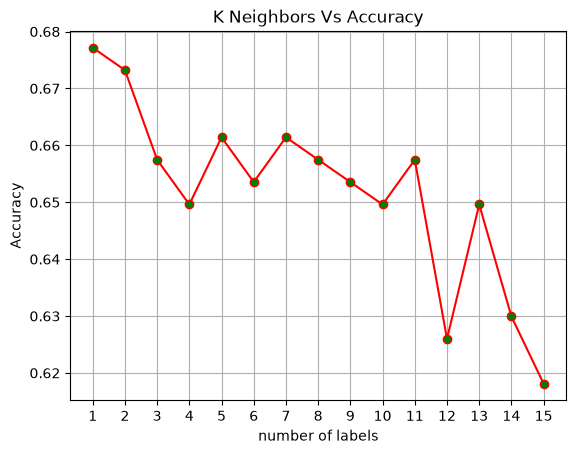

In [17]:
import matplotlib.pyplot as plt
plt.plot(df_scores.K,df_scores.score,marker='o',markerfacecolor='g',color='r')
plt.xticks(df_scores.K)
plt.title('K Neighbors Vs Accuracy')
plt.xlabel('number of labels')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show();

In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X_train)
X_tst_scl=scaler.transform(X_test)

In [24]:
knn=KNeighborsClassifier(n_neighbors=1)
knn.fit(X_scaled,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](4,)","['bus','opel','saab','van']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [27]:
y_pred=knn.predict(X_tst_scl)

In [28]:
accuracy_score(y_test,y_pred)

0.6850393700787402

In [29]:
Ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores=[]
for k in Ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_scaled,y_train)
    y_pred=knn.predict(X_tst_scl)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['K','score'])
df_scores.sort_values('score',ascending=False)

,K,score
2,3,0.728346
5,6,0.724409
14,15,0.720472
11,12,0.716535
7,8,0.712598
12,13,0.712598
13,14,0.712598
4,5,0.708661
3,4,0.704724
9,10,0.700787


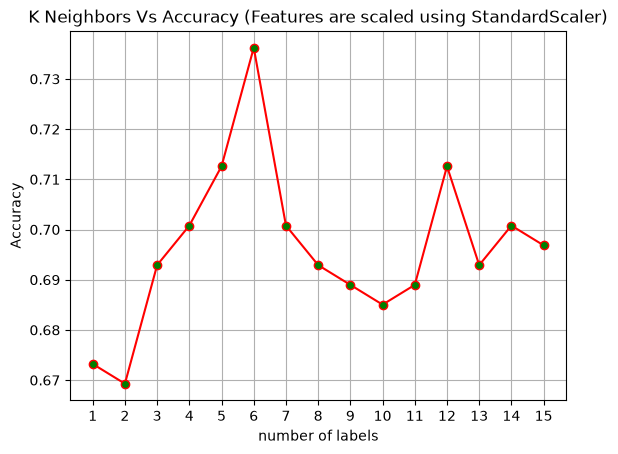

In [51]:
plt.plot(df_scores.K,df_scores.score,marker='o',markerfacecolor='g',color='r')
plt.xticks(df_scores.K)
plt.title('K Neighbors Vs Accuracy (Features are scaled using StandardScaler)')
plt.xlabel('number of labels')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show();

## training the same model using  pipeline

In [39]:
from sklearn.pipeline import Pipeline

In [40]:
Ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores=[]
scaler=StandardScaler()
for k in Ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    pipe=Pipeline([('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['K','score'])
df_scores.sort_values('score',ascending=False)

,K,score
2,3,0.728346
5,6,0.724409
14,15,0.720472
11,12,0.716535
7,8,0.712598
12,13,0.712598
13,14,0.712598
4,5,0.708661
3,4,0.704724
9,10,0.700787


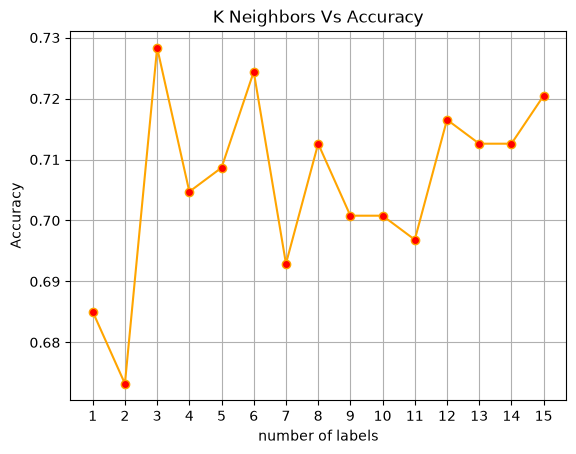

In [38]:
plt.plot(df_scores.K,df_scores.score,marker='o',markerfacecolor='r',color='orange')
plt.xticks(df_scores.K)
plt.title('K Neighbors Vs Accuracy')
plt.xlabel('number of labels')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show();

In [41]:
from sklearn.preprocessing import MinMaxScaler
Ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15]
scores=[]
scaler=MinMaxScaler()
for k in Ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    pipe=Pipeline([('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['K','score'])
df_scores.sort_values('score',ascending=False)

,K,score
5,6,0.736220
4,5,0.712598
11,12,0.712598
6,7,0.700787
3,4,0.700787
13,14,0.700787
14,15,0.696850
12,13,0.692913
7,8,0.692913
2,3,0.692913


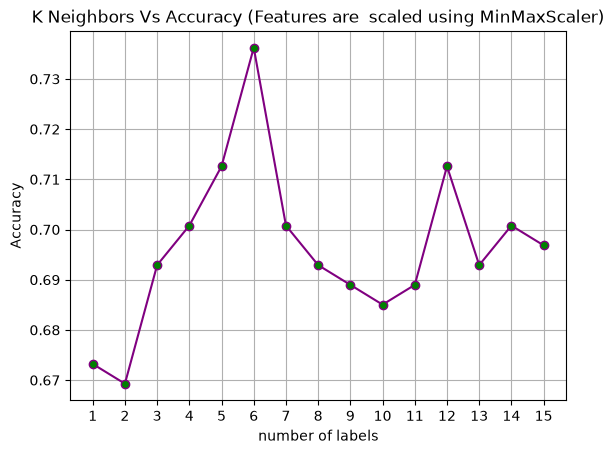

In [49]:
plt.plot(df_scores.K,df_scores.score,marker='o',markerfacecolor='green',color='purple')
plt.xticks(df_scores.K)
plt.title('K Neighbors Vs Accuracy (Features are scaled using MinMaxScaler)')
plt.xlabel('number of labels')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show();